# Question A

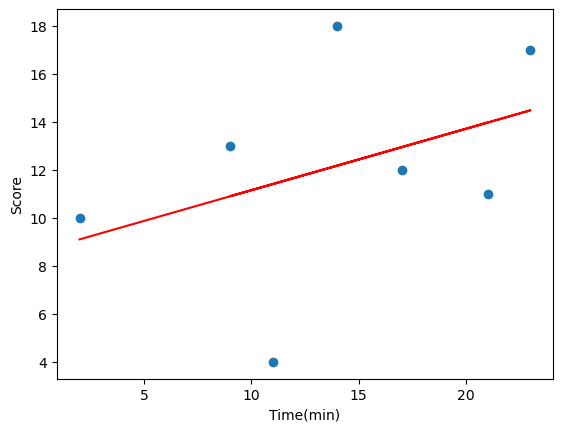

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize

time = np.array([2, 23, 17, 11, 9, 14, 21])
score = np.array([10, 17, 12, 4, 13, 18, 11])

[a, b] = np.polyfit(time, score, 1)
plt.scatter(time, score)
plt.plot(time, a * time + b, 'r')
plt.xlabel('Time(min)') 
plt.ylabel('Score')
plt.show()

# Question B


0
30
60
90


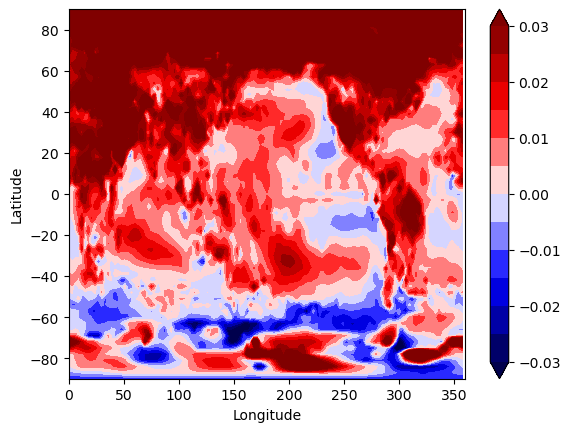

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

loadfile = 't2ma_erai.npz'
t2ma_dataset = np.load(loadfile)
t2ma = t2ma_dataset['t2ma']
lon2 = t2ma_dataset['lon2']
lat2 = t2ma_dataset['lat2']
y = t2ma_dataset['y']
m = t2ma_dataset['m']

[imt, jmt, tmt] = t2ma.shape
a_t2ma = np.zeros((imt, jmt))
b_t2ma = np.zeros((imt, jmt))
detrended_t2ma = np.zeros((imt, jmt, tmt))

mon = np.arange(1982, 2022, 1/12)

is_sea_grids_3D = (np.isnan(t2ma)==True)
t2ma[is_sea_grids_3D]=0
#print("len(mon):", len(mon))
#print("t2ma shape:", t2ma.shape)
for ii in range(0, imt):
    for jj in range(0, jmt):
        [a_t2ma[ii, jj], b_t2ma[ii, jj]] = np.polyfit(mon, t2ma[ii, jj, :], 1)
        detrended_t2ma[ii, jj, :] = t2ma[ii, jj, :] - (a_t2ma[ii, jj]*mon + b_t2ma[ii, jj])
    if (ii % 30 == 0):
        print(ii)
is_sea_grids_2D = np.squeeze(is_sea_grids_3D[:, :, 0])
a_t2ma[is_sea_grids_2D] = np.nan
b_t2ma[is_sea_grids_2D] = np.nan
detrended_t2ma[is_sea_grids_2D] = np.nan

vmin = -0.03
vmax = 0.03
vint = 0.005
plt.figure()
cm = plt.get_cmap('seismic')
cs = plt.contourf(lon2, lat2, a_t2ma, cmap=cm, norm=Normalize(vmin=vmin, vmax=vmax), levels=np.arange(vmin,vmax+vint,vint), extend='both')

plt.colorbar(cs)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
title = 't2ma trend'
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.show()

図の傾向を見ると、温暖化は南半球より北半球のほうが速く、海よりも陸地のほうが速く進んでいます。特に北半球の中高緯度や陸域で上昇傾向が強く、南大洋の一部では低下や弱い変化も見られます

# Question C

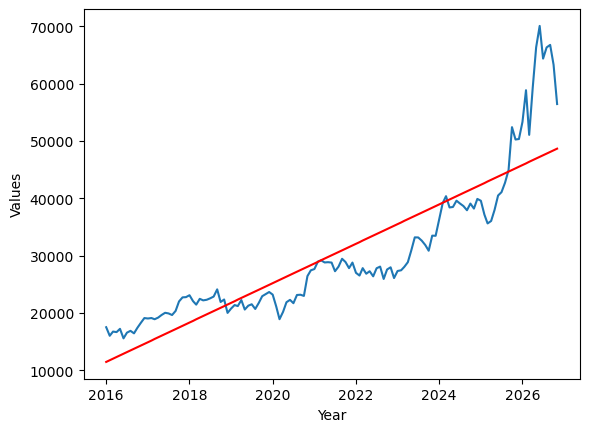

In [29]:
# 处理表格数据为shift_jis数据
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

filepath = "nikkei_stock_average_monthly_jp.csv"

# 这样的话就不用genfromtxt,df就是读出来的数据
df = pd.read_csv(filepath, encoding="shift_jis")
#print(df.head())
df = df.dropna() # 删除包含NaN的行
df['データ日付'] = pd.to_datetime(df['データ日付']) # 将字符串转化成日期
df = df.set_index('データ日付')
data = df['終値']
mon = np.arange(len(data))
plt.plot(data.index, data.values)
[a, b] = np.polyfit(mon, data.values, 1) # 要保持数据长度相同
plt.plot(data.index, a * mon + b, 'r')
plt.xlabel("Year")
plt.ylabel("Values")
plt.show()

#df.dtypes # 检查数据类型


日経平均株価の月次終値と、最小二乗法によって求めた線形トレンドを図に示した。短期的には株価の上昇と下落が繰り返されているが、長期的には上昇傾向が見られる。この理由として、企業業績の改善、円安の進行、金融政策などの影響が考えられる。一方、世界経済の変化や新型コロナウイルスの感染拡大などによって、一時的に株価が下落した時期もある。線形近似を行うことで、このような短期的な変動を含むデータから、長期的な変化傾向を把握することができる。

# Question D